Implement Local Binary Pattern (LBP) on a grayscale image.

LBP is a technique used in image processing to identify texture patterns.

How it works:
1. Take a 3×3 pixel window.
2. Consider the center pixel.
3. Compare all 8 neighbouring pixels with the center.
4. If a neighbour is greater than or equal to the center, assign 1.
5. Otherwise, assign 0.
6. Convert the 8 binary values into a decimal number.



Image denoising
Image denoising means removing unwanted noise from an image while preserving important details.

Gaussian noise: Random noise that follows a Gaussian (normal) distribution. It makes the image look grainy.

Speckle noise: Multiplicative noise that creates a grainy or spotted appearance.

Four filters
Filter      	Basic working

Wiener ---      Uses local mean and variance to reduce noise.


Median  ---- 	Replaces a pixel with the median of neighbouring pixels.

Gaussian ----	Uses a weighted average of neighbouring pixels.

Bilateral ---- 	Smooths noise while preserving edges.

In [1]:
pip install numpy pillow matplotlib

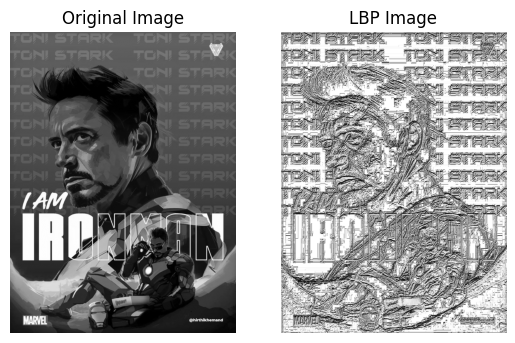

In [2]:

import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

# Read grayscale image
img = np.array(Image.open("input.jpg").convert("L"))

# Create output image
lbp = np.zeros((img.shape[0]-2, img.shape[1]-2), dtype=np.uint8)

# Apply Local Binary Pattern
for i in range(1, img.shape[0]-1):
    for j in range(1, img.shape[1]-1):

        center = img[i, j]
        binary = 0

        neighbors = [
            img[i-1, j-1], img[i-1, j],
            img[i-1, j+1], img[i, j+1],
            img[i+1, j+1], img[i+1, j],
            img[i+1, j-1], img[i, j-1]
        ]

        for k in range(8):
            if neighbors[k] >= center:
                binary += (1 << (7-k))

        lbp[i-1, j-1] = binary

# Display results
plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(lbp, cmap='gray')
plt.title("LBP Image")
plt.axis("off")

plt.show()


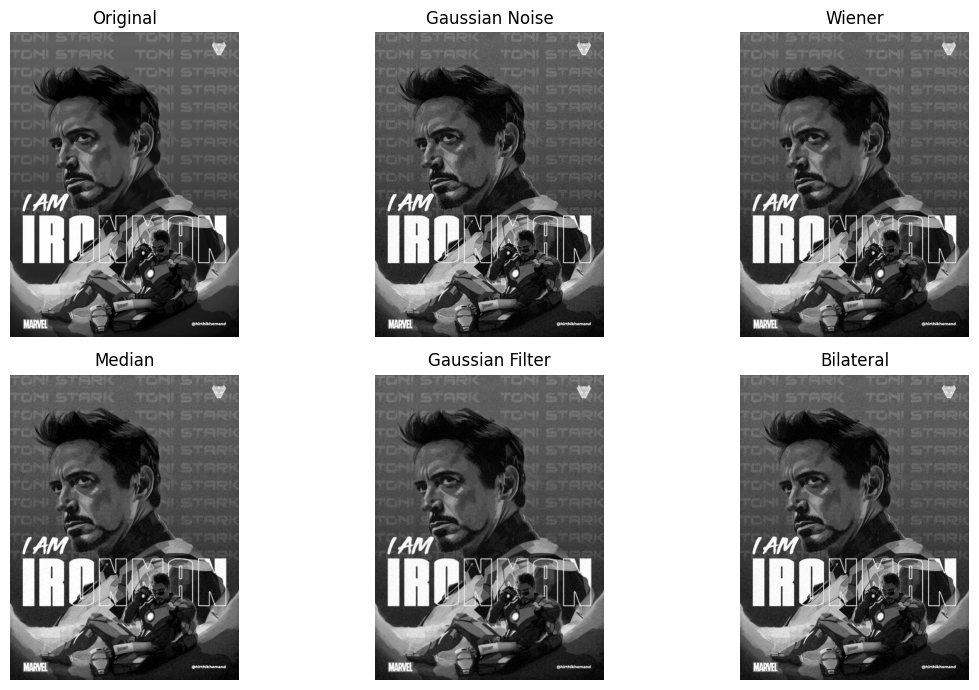

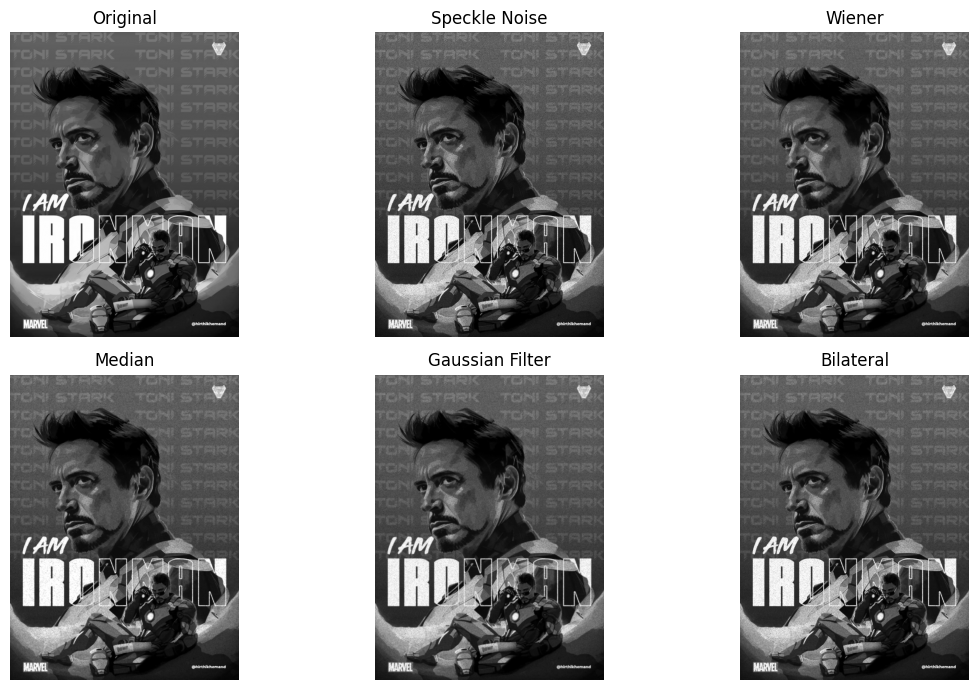

In [3]:

import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

# Read grayscale image
img = np.array(Image.open("input.jpg").convert("L"), dtype=float)

# Normalize image
img = img / 255.0

# Add Gaussian noise
gaussian_noise = img + np.random.normal(0, 0.05, img.shape)
gaussian_noise = np.clip(gaussian_noise, 0, 1)

# Add Speckle noise
speckle_noise = img + img * np.random.normal(0, 0.15, img.shape)
speckle_noise = np.clip(speckle_noise, 0, 1)


# Function for padding
def padding(image, size):
    p = size // 2
    return np.pad(image, p, mode='reflect')


# Wiener Filter
def wiener_filter(image, size=3):
    padded = padding(image, size)
    result = np.zeros_like(image)

    noise_var = 0.0025

    for i in range(image.shape[0]):
        for j in range(image.shape[1]):
            window = padded[i:i+size, j:j+size]

            local_mean = np.mean(window)
            local_var = np.var(window)

            result[i, j] = (
                local_mean +
                max(local_var - noise_var, 0) /
                (local_var + 1e-10) *
                (image[i, j] - local_mean)
            )

    return np.clip(result, 0, 1)


# Median Filter
def median_filter(image, size=3):
    padded = padding(image, size)
    result = np.zeros_like(image)

    for i in range(image.shape[0]):
        for j in range(image.shape[1]):
            window = padded[i:i+size, j:j+size]
            result[i, j] = np.median(window)

    return result


# Gaussian Filter
def gaussian_filter(image, size=3, sigma=1):
    p = size // 2
    x, y = np.mgrid[-p:p+1, -p:p+1]

    kernel = np.exp(-(x**2 + y**2)/(2*sigma**2))
    kernel = kernel / np.sum(kernel)

    padded = padding(image, size)
    result = np.zeros_like(image)

    for i in range(image.shape[0]):
        for j in range(image.shape[1]):
            window = padded[i:i+size, j:j+size]
            result[i, j] = np.sum(window * kernel)

    return np.clip(result, 0, 1)


# Bilateral Filter
def bilateral_filter(image, size=3, sigma_s=1, sigma_r=0.1):
    padded = padding(image, size)
    result = np.zeros_like(image)

    p = size // 2

    for i in range(image.shape[0]):
        for j in range(image.shape[1]):

            center = image[i, j]
            total = 0
            weight_sum = 0

            for m in range(size):
                for n in range(size):

                    neighbor = padded[i+m, j+n]

                    spatial = np.exp(
                        -((m-p)**2 + (n-p)**2) /
                        (2*sigma_s**2)
                    )

                    intensity = np.exp(
                        -((neighbor-center)**2) /
                        (2*sigma_r**2)
                    )

                    weight = spatial * intensity

                    total += neighbor * weight
                    weight_sum += weight

            result[i, j] = total / weight_sum

    return np.clip(result, 0, 1)


# Apply filters to Gaussian noise
g_wiener = wiener_filter(gaussian_noise)
g_median = median_filter(gaussian_noise)
g_gaussian = gaussian_filter(gaussian_noise)
g_bilateral = bilateral_filter(gaussian_noise)

# Apply filters to Speckle noise
s_wiener = wiener_filter(speckle_noise)
s_median = median_filter(speckle_noise)
s_gaussian = gaussian_filter(speckle_noise)
s_bilateral = bilateral_filter(speckle_noise)


# Display Gaussian noise results
images1 = [
    img, gaussian_noise, g_wiener,
    g_median, g_gaussian, g_bilateral
]

titles1 = [
    "Original", "Gaussian Noise", "Wiener",
    "Median", "Gaussian Filter", "Bilateral"
]

plt.figure(figsize=(12, 7))

for i in range(6):
    plt.subplot(2, 3, i+1)
    plt.imshow(images1[i], cmap='gray', vmin=0, vmax=1)
    plt.title(titles1[i])
    plt.axis("off")

plt.tight_layout()
plt.show()


# Display Speckle noise results
images2 = [
    img, speckle_noise, s_wiener,
    s_median, s_gaussian, s_bilateral
]

titles2 = [
    "Original", "Speckle Noise", "Wiener",
    "Median", "Gaussian Filter", "Bilateral"
]

plt.figure(figsize=(12, 7))

for i in range(6):
    plt.subplot(2, 3, i+1)
    plt.imshow(images2[i], cmap='gray', vmin=0, vmax=1)
    plt.title(titles2[i])
    plt.axis("off")

plt.tight_layout()
plt.show()


In [4]:
pip install opencv-python numpy matplotlib

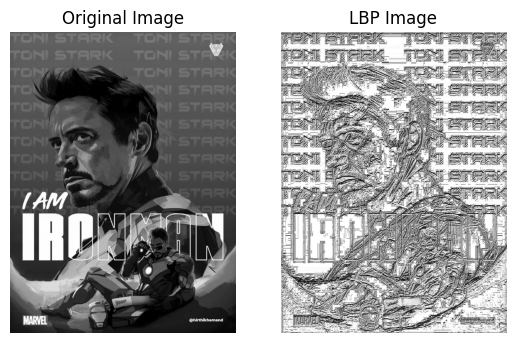

In [5]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read grayscale image
img = cv2.imread("input.jpg", 0)

# Create LBP output
lbp = np.zeros((img.shape[0]-2, img.shape[1]-2), dtype=np.uint8)

# Calculate LBP
for i in range(1, img.shape[0]-1):
    for j in range(1, img.shape[1]-1):

        center = img[i, j]

        neighbors = [
            img[i-1, j-1], img[i-1, j],
            img[i-1, j+1], img[i, j+1],
            img[i+1, j+1], img[i+1, j],
            img[i+1, j-1], img[i, j-1]
        ]

        value = 0

        for k in range(8):
            if neighbors[k] >= center:
                value += 1 << (7-k)

        lbp[i-1, j-1] = value

# Display images
plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(lbp, cmap='gray')
plt.title("LBP Image")
plt.axis("off")

plt.show()


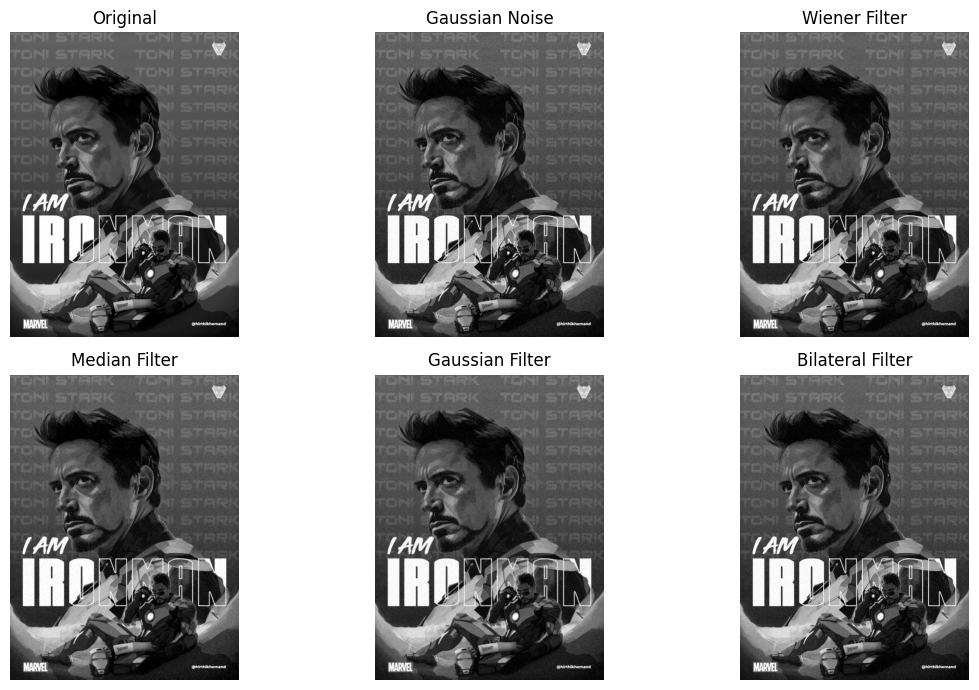

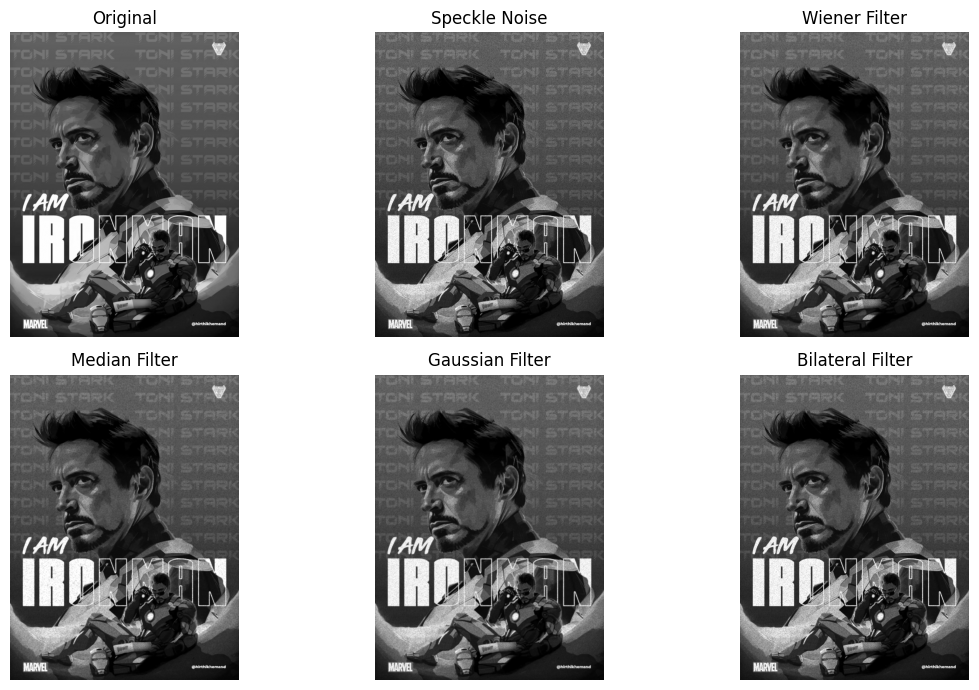

In [6]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

# Read grayscale image
img = cv2.imread("input.jpg", 0)

# Convert image to float
img_float = img.astype(np.float32) / 255.0

# Add Gaussian noise
gaussian_noise = img_float + np.random.normal(
    0, 0.05, img_float.shape
).astype(np.float32)

gaussian_noise = np.clip(gaussian_noise, 0, 1)

# Add Speckle noise
speckle_noise = img_float + img_float * np.random.normal(
    0, 0.15, img_float.shape
).astype(np.float32)

speckle_noise = np.clip(speckle_noise, 0, 1)


# Wiener Filter using OpenCV boxFilter
def wiener_filter(image, size=3):

    mean = cv2.boxFilter(
        image, -1, (size, size),
        normalize=True
    )

    mean_square = cv2.boxFilter(
        image**2, -1, (size, size),
        normalize=True
    )

    variance = mean_square - mean**2

    noise_var = 0.0025

    result = mean + (
        np.maximum(variance - noise_var, 0) /
        (variance + 1e-10)
    ) * (image - mean)

    return np.clip(result, 0, 1)


# Median Filter
def median_filter(image, size=3):
    image_uint8 = (image * 255).astype(np.uint8)

    result = cv2.medianBlur(image_uint8, size)

    return result.astype(np.float32) / 255.0


# Gaussian Filter
def gaussian_filter(image, size=3):
    result = cv2.GaussianBlur(
        image, (size, size), 0
    )

    return np.clip(result, 0, 1)


# Bilateral Filter
def bilateral_filter(image, size=3):
    result = cv2.bilateralFilter(
        image, size, 0.1, 1.0
    )

    return np.clip(result, 0, 1)


# Apply filters to Gaussian noise
g_wiener = wiener_filter(gaussian_noise)
g_median = median_filter(gaussian_noise)
g_gaussian = gaussian_filter(gaussian_noise)
g_bilateral = bilateral_filter(gaussian_noise)

# Apply filters to Speckle noise
s_wiener = wiener_filter(speckle_noise)
s_median = median_filter(speckle_noise)
s_gaussian = gaussian_filter(speckle_noise)
s_bilateral = bilateral_filter(speckle_noise)


# Display results
def show_results(original, noisy, results, noise_name):

    images = [
        original, noisy,
        results[0], results[1],
        results[2], results[3]
    ]

    titles = [
        "Original", noise_name,
        "Wiener Filter", "Median Filter",
        "Gaussian Filter", "Bilateral Filter"
    ]

    plt.figure(figsize=(12, 7))

    for i in range(6):
        plt.subplot(2, 3, i+1)
        plt.imshow(images[i], cmap='gray', vmin=0, vmax=1)
        plt.title(titles[i])
        plt.axis("off")

    plt.tight_layout()
    plt.show()


show_results(
    img_float, gaussian_noise,
    [g_wiener, g_median, g_gaussian, g_bilateral],
    "Gaussian Noise"
)

show_results(
    img_float, speckle_noise,
    [s_wiener, s_median, s_gaussian, s_bilateral],
    "Speckle Noise"
)
